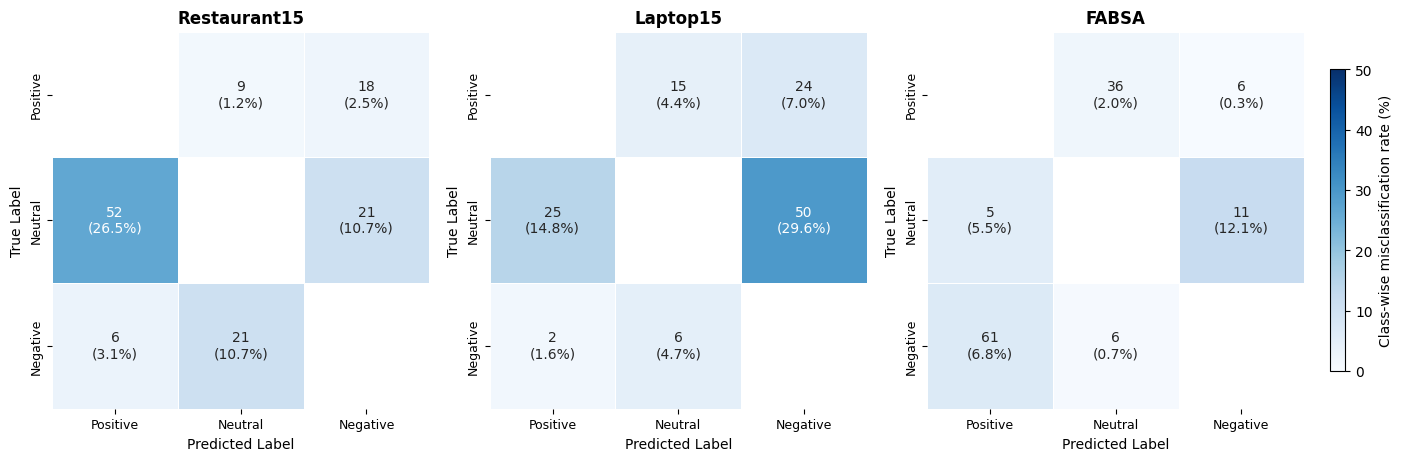

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Class labels
labels = ["Positive", "Neutral", "Negative"]

# Misclassification counts for each dataset
datasets = {
    "Restaurant15": np.array([
        [0, 9, 18],
        [52, 0, 21],
        [6, 21, 0]
    ]),
    "Laptop15": np.array([
        [0, 15, 24],
        [25, 0, 50],
        [2, 6, 0]
    ]),
    "FABSA": np.array([
        [0, 36, 6],
        [5, 0, 11],
        [61, 6, 0]
    ])
}

# Number of instances in each true class
class_counts = {
    "Restaurant15": [728, 196, 196],
    "Laptop15": [341, 169, 128],
    "FABSA": [1825, 91, 896]
}

# Create subplots with constrained layout
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 4.5),
    layout="constrained"
)

# Common colour scale for all datasets
norm = Normalize(vmin=0, vmax=50)
cmap = plt.get_cmap("Blues")

# Mask diagonal cells
mask = np.eye(3, dtype=bool)

# Generate each heatmap
for ax, (name, cm) in zip(axes, datasets.items()):

    counts = class_counts[name]

    # Calculate row-wise misclassification percentages
    error_rates = np.zeros(cm.shape, dtype=float)
    annot = np.empty(cm.shape, dtype=object)

    for i in range(3):
        for j in range(3):

            if i == j:
                annot[i, j] = "--"

            else:
                pct = 100 * cm[i, j] / counts[i]

                error_rates[i, j] = pct

                annot[i, j] = (
                    f"{cm[i, j]}\n({pct:.1f}%)"
                )

    # Plot heatmap
    sns.heatmap(
        error_rates,
        annot=annot,
        fmt="",
        mask=mask,
        cmap=cmap,
        norm=norm,
        xticklabels=labels,
        yticklabels=labels,
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        square=True,
        ax=ax,
        annot_kws={"size": 10}
    )

    # Titles and axis labels
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label", fontsize=10)
    ax.set_ylabel("True Label", fontsize=10)

    ax.tick_params(axis="both", labelsize=9)

# Create one shared colour bar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes,
    label="Class-wise misclassification rate (%)",
    shrink=0.8,
    pad=0.02
)

# Save high-resolution figure
plt.savefig(
    "apc_error_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# Display figure
plt.show()
